# 02. Clean Baseline Training

This notebook trains and evaluates the clean-label baseline model. The baseline provides the reference performance used to assess the effects of synthetic label noise and the effectiveness of subsequent mitigation methods.

**Workflow:** configuration → dataset preparation → DenseNet-121 → training → checkpointing → evaluation and visualisation.


In [1]:
import os
import gc
import time
import json
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score

SEED = 132
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM: 8.55 GB


## 1. Configuration and Reproducibility

Define dataset paths, target pathologies, training hyperparameters, random seeds, device settings, and output locations used throughout the baseline experiment.


In [2]:
RAW_DIR = os.path.join('..', 'data', 'raw')
PROCESSED_DIR = os.path.join('..', 'data', 'processed')
TEST_DIR = os.path.join('..', 'data', 'test')
MODELS_DIR = os.path.join('..', 'models')
RESULTS_DIR = os.path.join('..', 'results')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

TARGET_PATHOLOGIES = [
    'Cardiomegaly', 'Edema', 'Consolidation',
    'Atelectasis', 'Pleural Effusion'
]

CONFIG = {
    'batch_size': 32,
    'num_workers': 0,
    'learning_rate': 1e-4,
    'num_epochs': 5,
    'image_size': 224,
    'weight_decay': 1e-5,
    'early_stopping_patience': 2,
    'experiment_name': 'baseline_clean',
}

print(json.dumps(CONFIG, indent=2))

{
  "batch_size": 32,
  "num_workers": 0,
  "learning_rate": 0.0001,
  "num_epochs": 5,
  "image_size": 224,
  "weight_decay": 1e-05,
  "early_stopping_patience": 2,
  "experiment_name": "baseline_clean"
}


## 2. Dataset and Data Loading

Define the CheXpert dataset class and preprocessing pipeline. Images are loaded from the original data directory, converted to the required format, transformed, and paired with the five target pathology labels.


In [3]:
class CheXpertDataset(Dataset):
    def __init__(self, csv_path, data_dir, pathologies, transform=None):
        self.df = pd.read_csv(csv_path)
        self.data_dir = data_dir
        self.pathologies = pathologies
        self.transform = transform
        
        # Pre-convert for faster access
        self.labels = self.df[pathologies].values.astype(np.float32)
        self.paths = self.df['Path'].values
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.data_dir, self.paths[idx])
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        labels = torch.from_numpy(self.labels[idx])
        return image, labels


train_transform = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

## 3. Train, Validation, and Test DataLoaders

Create datasets and data loaders for the clean training, validation, and test splits. These loaders provide the data used for optimisation and final evaluation.


In [4]:
train_dataset = CheXpertDataset(
    csv_path=os.path.join(PROCESSED_DIR, 'train_clean.csv'),
    data_dir=RAW_DIR,
    pathologies=TARGET_PATHOLOGIES,
    transform=train_transform
)

val_dataset = CheXpertDataset(
    csv_path=os.path.join(PROCESSED_DIR, 'val_clean.csv'),
    data_dir=RAW_DIR,
    pathologies=TARGET_PATHOLOGIES,
    transform=eval_transform
)

test_dataset = CheXpertDataset(
    csv_path=os.path.join(PROCESSED_DIR, 'test_official.csv'),
    data_dir=TEST_DIR,  # Different! Test images live in data/test/
    pathologies=TARGET_PATHOLOGIES,
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'],
    shuffle=True, num_workers=CONFIG['num_workers'], pin_memory=True,
)

val_loader = DataLoader(
    val_dataset, batch_size=CONFIG['batch_size'],
    shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True,
)

test_loader = DataLoader(
    test_dataset, batch_size=CONFIG['batch_size'],
    shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True,
)

print(f"Train: {len(train_dataset):,} images, {len(train_loader):,} batches")
print(f"Val:   {len(val_dataset):,} images, {len(val_loader):,} batches")
print(f"Test:  {len(test_dataset):,} images, {len(test_loader):,} batches")
print(f"Estimated epoch time: {len(train_loader) * 0.2 / 60:.1f}-{len(train_loader) * 0.5 / 60:.1f} minutes")

Train: 191,027 images, 5,970 batches
Val:   202 images, 7 batches
Test:  518 images, 17 batches
Estimated epoch time: 19.9-49.8 minutes


## 4. DenseNet-121 Model

Initialise the ImageNet-pretrained DenseNet-121 backbone and adapt the classification layer for five-label chest X-ray prediction.


In [5]:
def build_densenet121(num_classes, pretrained=True):
    weights = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.densenet121(weights=weights)
    in_features = model.classifier.in_features
    model.classifier = nn.Linear(in_features, num_classes)
    return model

model = build_densenet121(num_classes=len(TARGET_PATHOLOGIES), pretrained=True)
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: DenseNet-121")
print(f"Trainable parameters: {n_params:,}")
print(f"Output size: {len(TARGET_PATHOLOGIES)} (multi-label)")

Model: DenseNet-121
Trainable parameters: 6,958,981
Output size: 5 (multi-label)


## 5. Optimisation Setup

Configure the multi-label loss function, optimiser, learning-rate scheduling, and mixed-precision training components.


In [6]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=CONFIG['learning_rate'],
    weight_decay=CONFIG['weight_decay']
)

scaler = GradScaler('cuda') if device.type == 'cuda' else None

print(f"Loss: {type(criterion).__name__}")
print(f"Optimizer: {type(optimizer).__name__} (lr={CONFIG['learning_rate']})")
print(f"Mixed precision: {'ON' if scaler is not None else 'OFF'}")

Loss: BCEWithLogitsLoss
Optimizer: AdamW (lr=0.0001)
Mixed precision: ON


## 6. Training and Validation Functions

Define the reusable training and validation routines, including loss computation, gradient updates, AUC calculation, and epoch timing.


In [7]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()
    total_loss = 0.0
    n_batches = 0
    start = time.time()
    
    for i, (images, labels) in enumerate(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)
        
        if scaler is not None:
            with autocast('cuda'):
                logits = model(images)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        
        total_loss += loss.item()
        n_batches += 1
        
        if (i + 1) % 100 == 0:
            elapsed = time.time() - start
            eta = elapsed / (i + 1) * (len(loader) - i - 1)
            print(f"  Batch {i+1:>5}/{len(loader)} | loss={loss.item():.4f} | "
                  f"elapsed={elapsed/60:.1f}min | ETA={eta/60:.1f}min")
    
    return total_loss / n_batches


@torch.no_grad()
def evaluate(model, loader, criterion, device, pathologies):
    model.eval()
    total_loss = 0.0
    all_logits = []
    all_labels = []
    
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        with autocast('cuda', enabled=device.type == 'cuda'):
            logits = model(images)
            loss = criterion(logits, labels)
        
        total_loss += loss.item()
        all_logits.append(logits.float().cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    
    all_logits = np.concatenate(all_logits)
    all_labels = np.concatenate(all_labels)
    all_probs = 1 / (1 + np.exp(-all_logits))
    
    aucs = {}
    for i, path in enumerate(pathologies):
        if len(np.unique(all_labels[:, i])) > 1:
            aucs[path] = roc_auc_score(all_labels[:, i], all_probs[:, i])
        else:
            aucs[path] = float('nan')
    
    mean_auc = np.nanmean(list(aucs.values()))
    return total_loss / len(loader), mean_auc, aucs, all_probs, all_labels

## 7. Train the Clean Baseline

Run the training loop, monitor validation performance, and retain the checkpoint with the best validation AUC.


In [8]:
history = {
    'train_loss': [], 'val_loss': [], 'val_auc': [],
    'per_pathology_auc': [], 'epoch_time': []
}
best_val_auc = 0.0
epochs_no_improve = 0
best_model_path = os.path.join(MODELS_DIR, f"{CONFIG['experiment_name']}_best.pt")

print(f"Starting training: {CONFIG['experiment_name']}")
print(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 70)

training_start = time.time()

for epoch in range(1, CONFIG['num_epochs'] + 1):
    epoch_start = time.time()
    print(f"\nEpoch {epoch}/{CONFIG['num_epochs']}")
    print("-" * 70)
    
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
    
    print("  Evaluating on validation set...")
    val_loss, val_auc, per_path_auc, _, _ = evaluate(
        model, val_loader, criterion, device, TARGET_PATHOLOGIES
    )
    
    epoch_time = time.time() - epoch_start
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    history['per_pathology_auc'].append(per_path_auc)
    history['epoch_time'].append(epoch_time)
    
    print(f"  Train loss: {train_loss:.4f}")
    print(f"  Val loss:   {val_loss:.4f}")
    print(f"  Val AUC:    {val_auc:.4f}")
    print(f"  Per-pathology AUC:")
    for path, auc in per_path_auc.items():
        print(f"    {path:20s}: {auc:.4f}")
    print(f"  Epoch time: {epoch_time/60:.1f} minutes")
    
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        epochs_no_improve = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc': val_auc,
            'per_pathology_auc': per_path_auc,
            'config': CONFIG,
        }, best_model_path)
        print(f"  New best model saved (AUC={val_auc:.4f})")
    else:
        epochs_no_improve += 1
        print(f"  No improvement for {epochs_no_improve} epoch(s)")
        if epochs_no_improve >= CONFIG['early_stopping_patience']:
            print(f"  Early stopping triggered.")
            break

total_time = time.time() - training_start
print("\n" + "=" * 70)
print(f"Training complete. Total time: {total_time/60:.1f} minutes")
print(f"Best val AUC: {best_val_auc:.4f}")
print(f"Best model saved to: {best_model_path}")

Starting training: baseline_clean
Timestamp: 2026-07-28 17:05:41

Epoch 1/5
----------------------------------------------------------------------
  Batch   100/5970 | loss=0.5312 | elapsed=0.3min | ETA=18.2min
  Batch   200/5970 | loss=0.4537 | elapsed=0.6min | ETA=17.4min
  Batch   300/5970 | loss=0.6855 | elapsed=0.9min | ETA=16.9min
  Batch   400/5970 | loss=0.4870 | elapsed=1.2min | ETA=16.5min
  Batch   500/5970 | loss=0.3956 | elapsed=1.5min | ETA=16.1min
  Batch   600/5970 | loss=0.4547 | elapsed=1.8min | ETA=15.8min
  Batch   700/5970 | loss=0.5004 | elapsed=2.0min | ETA=15.4min
  Batch   800/5970 | loss=0.4631 | elapsed=2.3min | ETA=15.1min
  Batch   900/5970 | loss=0.4477 | elapsed=2.6min | ETA=14.8min
  Batch  1000/5970 | loss=0.4225 | elapsed=2.9min | ETA=14.5min
  Batch  1100/5970 | loss=0.4527 | elapsed=3.2min | ETA=14.2min
  Batch  1200/5970 | loss=0.4787 | elapsed=3.5min | ETA=13.9min
  Batch  1300/5970 | loss=0.5070 | elapsed=3.8min | ETA=13.6min
  Batch  1400/5970 | 

## 8. Save Training History

Save the experiment configuration, learning history, and best validation results for reproducibility and later analysis.


In [9]:
history_path = os.path.join(RESULTS_DIR, f"{CONFIG['experiment_name']}_history.json")

history_json = {
    'config': CONFIG,
    'best_val_auc': float(best_val_auc),
    'total_time_minutes': total_time / 60,
    'train_loss': [float(x) for x in history['train_loss']],
    'val_loss': [float(x) for x in history['val_loss']],
    'val_auc': [float(x) for x in history['val_auc']],
    'epoch_time': history['epoch_time'],
    'per_pathology_auc': [{k: float(v) for k, v in d.items()} for d in history['per_pathology_auc']],
}

with open(history_path, 'w') as f:
    json.dump(history_json, f, indent=2)

print(f"History saved to: {history_path}")

History saved to: ..\results\baseline_clean_history.json


## 9. Visualise Training Dynamics

Plot training loss, validation loss, and validation AUC across epochs to inspect convergence and model behaviour.


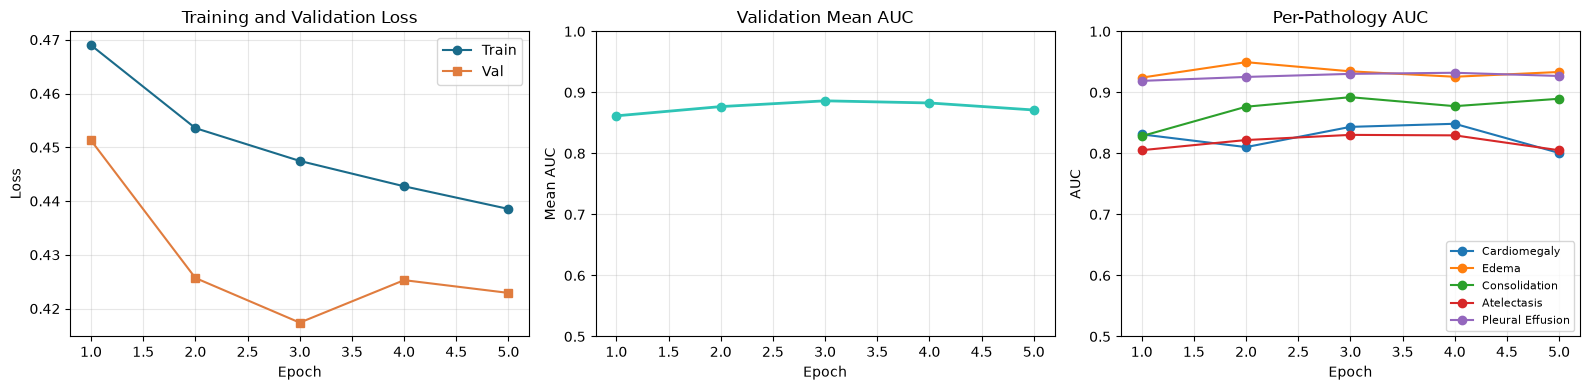

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

epochs = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs, history['train_loss'], 'o-', label='Train', color='#1A6B8A')
axes[0].plot(epochs, history['val_loss'], 's-', label='Val', color='#E07C3E')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history['val_auc'], 'o-', color='#2EC4B6', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean AUC')
axes[1].set_title('Validation Mean AUC')
axes[1].grid(alpha=0.3)
axes[1].set_ylim([0.5, 1.0])

for path in TARGET_PATHOLOGIES:
    aucs = [h[path] for h in history['per_pathology_auc']]
    axes[2].plot(epochs, aucs, 'o-', label=path)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('AUC')
axes[2].set_title('Per-Pathology AUC')
axes[2].legend(fontsize=8, loc='lower right')
axes[2].grid(alpha=0.3)
axes[2].set_ylim([0.5, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f"{CONFIG['experiment_name']}_curves.png"), dpi=100, bbox_inches='tight')
plt.show()

## 10. Evaluate the Best Checkpoint

Reload the best-performing checkpoint and evaluate it on the held-out test set, reporting overall and pathology-level performance.


In [11]:
checkpoint = torch.load(best_model_path, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

print("=" * 70)
print(f"BASELINE RESULTS ON VALIDATION SET - {CONFIG['experiment_name']}")
print("=" * 70)
print(f"Best epoch:       {checkpoint['epoch']}")
print(f"Best val AUC:     {checkpoint['val_auc']:.4f}")
print(f"\nPer-pathology AUC:")
for path, auc in checkpoint['per_pathology_auc'].items():
    print(f"  {path:20s}: {auc:.4f}")
print("=" * 70)

print("\nReference (CheXpert paper, DenseNet-121, 30-model ensemble on full v1.0):")
reference = {
    'Cardiomegaly': 0.854, 'Edema': 0.941, 'Consolidation': 0.939,
    'Atelectasis': 0.858, 'Pleural Effusion': 0.936
}
for path, auc in reference.items():
    print(f"  {path:20s}: {auc:.4f}")

BASELINE RESULTS ON VALIDATION SET - baseline_clean
Best epoch:       3
Best val AUC:     0.8861

Per-pathology AUC:
  Cardiomegaly        : 0.8435
  Edema               : 0.9344
  Consolidation       : 0.8921
  Atelectasis         : 0.8303
  Pleural Effusion    : 0.9303

Reference (CheXpert paper, DenseNet-121, 30-model ensemble on full v1.0):
  Cardiomegaly        : 0.8540
  Edema               : 0.9410
  Consolidation       : 0.9390
  Atelectasis         : 0.8580
  Pleural Effusion    : 0.9360


## 11. Save Final Baseline Results

Store the final baseline metrics and associated experiment outputs so they can be used as the clean reference in later noise experiments.


In [12]:
# Load best model checkpoint
checkpoint = torch.load(best_model_path, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_auc, test_per_path, _, _ = evaluate(
    model, test_loader, criterion, device, TARGET_PATHOLOGIES
)

print("=" * 70)
print("OFFICIAL TEST SET EVALUATION")
print(f"{len(test_dataset)} studies, 5-radiologist consensus ground truth")
print("=" * 70)
print(f"Test Mean AUC: {test_auc:.4f}")
print(f"\nPer-pathology AUC:")
for path, auc in test_per_path.items():
    print(f"  {path:20s}: {auc:.4f}")
print("=" * 70)

# Save test results
test_results = {
    'test_mean_auc': float(test_auc),
    'test_per_pathology_auc': {k: float(v) for k, v in test_per_path.items()},
    'test_loss': float(test_loss),
    'test_set_size': len(test_dataset)
}
test_results_path = os.path.join(RESULTS_DIR, f"{CONFIG['experiment_name']}_test_results.json")
with open(test_results_path, 'w') as f:
    json.dump(test_results, f, indent=2)
print(f"\nTest results saved to: {test_results_path}")

OFFICIAL TEST SET EVALUATION
518 studies, 5-radiologist consensus ground truth
Test Mean AUC: 0.8902

Per-pathology AUC:
  Cardiomegaly        : 0.8947
  Edema               : 0.9092
  Consolidation       : 0.8380
  Atelectasis         : 0.8492
  Pleural Effusion    : 0.9597

Test results saved to: ..\results\baseline_clean_test_results.json
